## 12 — CIBERSORTx vs. XDec: biological and technical comparison

### Aim
* Compare CIBERSORTx (supervised regression against a fixed signature matrix) and XDec (unsupervised, reference-anchored, whole-tissue NMF) on the same TCGA-PAAD cohort, on two levels: a **biological** comparison (what each tool actually estimates, and why) and a **technical** comparison (algorithm, inputs, assumptions), plus three direct **quantitative/visual comparisons** requested for the paper-gene-list, n=150 setup: (1) a profile-vs-reference correlation heatmap for XDec, (2) the same visualization for CIBERSORTx, and (3) a per-cell-type proportion scatter between the two tools.
* Part 1 uses CIBERSORTx's standard **LM22** matrix (immune-only, different reference). Part 2 and 3 use a second CIBERSORTx run built on **the same Peng et al. single-cell reference as XDec** (same 10 cell types, same cohort) — Part 2 with XDec's local Stage-0 gene list, Part 3 with the paper's 282-gene Table S3 list.
* This supersedes the immune-proxy piece of the older `data/deconvolution/tool_comparison/` three-tool comparison (CIBERSORTx vs. TIMER vs. XDec), which used an early XDec run at **k=3** on the unfiltered n=182 cohort. Here XDec is run at **k=9** on the paper-aligned **n=150** cohort — the model this project has since settled on as its main reference point.

### Input
* `data/deconvolution/cibersortx/CIBERSORTx_Job1_Adjusted.txt` — CIBERSORTx LM22 output, 22 immune subtypes, n=182 (TCGA-PAAD, relative/standard mode)
* `data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx/{CIBERSORTx_Adjusted.txt,CIBERSORTx_sigmatrix_Adjusted.txt}` — CIBERSORTx run with a custom signature matrix built from the **same Peng et al. PDAC single-cell reference** XDec uses, same 10 cell-type categories, n=182 (column labels found shifted by one position — see the Data-quality check below — and corrected in place before use)
* `data/deconvolution/xdec/stage1_with_refs_k9_n150/{proportions.tsv,correlation.tsv,cell_type_profiles.tsv}` — XDec Stage 1, k=9, n=150, **local Stage-0 probes**, Peng et al. single-cell reference (`refs.tsv`)
* `data/deconvolution/xdec/stage1_with_refs_k9_n150_paperGenes/{proportions.tsv,correlation.tsv,cell_type_profiles.tsv}` — XDec Stage 1, k=9, n=150, **paper's 282-gene Table S3 list** ("Run A")
* `data/processed/TCGA-PAAD_TPM_raw.tsv` — bulk TPM, used only as an independent sanity check against canonical marker genes (not part of either tool's own pipeline)
* `data/deconvolution/xdec/TCGA-PAAD_counts_raw_n150.tsv` — the 150-sample cohort used to restrict all CIBERSORTx runs' n=182 to the common 150 samples

### Output
* A biological + technical comparison summary (markdown, below)
* Figure A: each tool's own estimated cell-type composition (mean proportion across samples), side by side (CIBERSORTx-LM22 vs. XDec, local gene list)
* Figure B: scatter comparison of XDec's immune-correlated profile against CIBERSORTx-LM22's aggregated Lymphoid/Myeloid scores, with Pearson/Spearman statistics
* Figure C: same-reference, same-10-cell-type grouped bar comparison (CIBERSORTx-Peng vs. XDec local-gene-list profile), plus a per-cell-type correlation table
* **Figure D**: XDec (paper genes, Run A) profile-vs-reference-expression correlation heatmap
* **Figure E**: the same visualization applied to CIBERSORTx-Peng's own inferred signature matrix vs. reference expression
* **Figure F**: per-cell-type proportion scatter, XDec Run A (paper genes) vs. CIBERSORTx-Peng, n=150

### Steps
* Load both tools' outputs; restrict all CIBERSORTx runs to the 150-sample cohort shared with XDec
* **Data-quality check**: validate CIBERSORTx-Peng's column labels against independent bulk marker-gene expression before trusting any downstream comparison — this caught and fixed a real off-by-one column-labeling bug in the `cibersortx_reference_choice_20261102` run's output files (see the dedicated cell below)
* Label each XDec profile by its best-correlating reference cell type (from `correlation.tsv`), flagging any profile that is not cleanly separable
* Aggregate CIBERSORTx-LM22's 22 subtypes into Lymphoid/Myeloid (standard grouping used in the prior three-tool comparison)
* Build the LM22 visualizations (A, B), the same-reference local-gene visualization (C), then the paper-gene-list heatmaps and scatter (D, E, F)

### Result
* **LM22 comparison (Part 1)**: the two tools are not directly comparable by magnitude (XDec sums to 1 over the whole tumor; CIBERSORTx-LM22 sums to 1 over the immune compartment only). At k=9/n=150 (local gene list), `Profile_7` is the single best match to all 10/10 reference cell types and shows a modest, significant positive correlation with CIBERSORTx-LM22 Lymphoid (r=0.295, p=2.4e-4).
* **Data-quality finding**: the Peng-reference CIBERSORTx run's column labels, as supplied, are shifted by one position — canonical markers (`KRT19`, `CD3D`, `MS4A1`, `PRSS1`, etc.) correlate in the *wrong* direction under the as-labeled columns and strongly in the *correct* direction after a one-position cyclic relabel (summed Spearman r across 4 markers: -0.08 as-supplied vs. +2.73 corrected). Fixed in place for all downstream use.
* **Same-reference, local gene list (Part 2)**: with the labeling bug fixed, `Profile_7`'s per-type correlations with CIBERSORTx-Peng are modest and don't form a single clean biological axis (significant positive with `T cell` r=0.31 and `neural cell` r=0.22; significant negative with `fibroblast` r=-0.34, `blood vessel endothelial cell` r=-0.20, `myeloid leukocyte` r=-0.17; null elsewhere).
* **Same-reference, paper gene list (Part 3) — the clearest result in this notebook**: where XDec Run A resolves a *distinct* profile (not the shared ambiguous one), agreement with CIBERSORTx-Peng is strong: `pancreatic ductal cell` (r=0.80, ρ=0.82), `fibroblast` (r=0.78, ρ=0.78), `pancreatic acinar cell` (r=0.73, ρ=0.95). Where multiple reference types collapse onto the one shared ambiguous profile (`Profile_8`), agreement is weak or null.

### Conclusion
* CIBERSORTx and XDec answer different biological questions with different technical machinery. Holding the reference and cell-type categories fixed isolates the comparison to algorithm alone — and the result is genuinely informative in both directions: XDec's distinctly-resolved profiles (ductal, fibroblast, acinar under the paper gene list) agree strongly with an independent, differently-built tool on the same reference, which is real, externally-verifiable evidence those specific profiles are picking up true biology. But every reference type that collapses onto the shared ambiguous profile loses that external validity along with its correlation specificity — directly connecting this project's long-running "ambiguous profile" problem to a measurable loss of real-world agreement, not just an internal diagnostic symptom. XDec's broader scope (the full tissue ecosystem, not just immune cells) remains a real, unique advantage over CIBERSORTx, and — for the profiles it resolves cleanly — a validated one.


### Biological comparison

| | **CIBERSORTx** (this run: LM22, standard mode) | **XDec** (this run: k=9, n=150) |
|---|---|---|
| **What it estimates** | Composition *within the immune infiltrate*: 22 immune cell subtypes (B/T/NK/monocyte/macrophage/DC/mast/granulocyte lineages). Proportions sum to 1 **across immune subtypes only** — it says nothing about what fraction of the tumor is immune vs. non-immune. | Composition of the **whole bulk tumor sample**: k=9 profiles, each a mixture-model component, proportions summing to 1 **across the whole sample** — cancer/epithelial, stromal, and immune compartments together. |
| **Reference basis** | LM22: a published, independently validated signature matrix built from FACS-sorted, bulk-profiled human immune cell populations (blood/lymphoid tissue derived) — mature, widely benchmarked, not specific to pancreas or PDAC. | This project's own export of the Peng et al. 2019 PDAC single-cell reference (GSA: CRA001160) — tissue- and disease-matched (pancreatic tumor microenvironment), but a single study, not independently cross-validated the way LM22 has been. |
| **Non-immune compartments** | Not modeled at all — cancer/ductal/acinar/stellate/fibroblast/endothelial/neural cells have no corresponding LM22 signature. | Modeled directly — profiles are matched (by correlation) to pancreatic acinar, ductal, enteroendocrine, stellate, fibroblast, endothelial, neural, T cell, B-lineage, and myeloid reference types. |
| **Biological payoff when it works** | A well-resolved, well-validated breakdown of *which* immune cells are present — useful for immune-infiltration questions specifically. | A potentially much richer picture (cancer-cell-state proportions, stromal composition, immune content, all jointly) — but only as reliable as the project's own reference and model-selection choices, which this investigation has spent considerable effort stress-testing. |
| **Known biological limitation (this project's data)** | Myeloid subtypes in particular are known to disagree with other tools' myeloid estimates (CIBERSORTx vs. TIMER myeloid: r=0.06, n.s. — see the older three-tool comparison) — a documented weak spot for *any* bulk-deconvolution myeloid estimate, not unique to this project. | One profile remains **broadly, non-specifically correlated with nearly every reference cell type** in every configuration tested across this entire investigation (cohort size, gene list, reference processing, k=9 through k=20) — most consistent with an unresolved NNLS/NMF artifact, or a real but reference-unmatchable tumor-epithelial signal, rather than a clean, assignable cell type. |
| **When run on the SAME reference (Part 2, below)** | Using a custom Peng-reference signature matrix, CIBERSORTx still cleanly resolves all 10 cell types into differentiated, non-degenerate proportions — supervised regression against a fixed matrix doesn't have an "ambiguous component" failure mode by construction. | Running XDec's own usual pipeline, holding the exact same reference and cell-type set fixed, still collapses most types onto the same single ambiguous profile — ruling out "wrong reference" as the explanation and pointing at the algorithm/fit itself. |

### Technical comparison

| | **CIBERSORTx** | **XDec** |
|---|---|---|
| **Algorithm** | ν-support-vector regression (CIBERSORT's core method) against a **fixed**, pre-built signature matrix, with CIBERSORTx's batch-correction ("B-mode") step on top. | Two-stage, semi-supervised: **Stage 0** selects informative genes via one-vs-rest differential expression against the single-cell reference; **Stage 1** jointly estimates k *unlabeled* profiles and per-sample proportions via non-negative matrix factorization, anchored (not fixed) by the reference; **Stage 2** refits full-transcriptome, cell-type-specific expression given the fixed Stage-1 proportions. |
| **Reference matrix** | Fixed and given — either the published LM22 matrix, or (Part 2) a custom matrix this project built from the same Peng et al. single-cell data XDec uses, via CIBERSORTx's own signature-matrix-building step. Either way, not re-derived at run time. | Built per-project from raw single-cell data; several processing choices (pseudo-bulking, depth-matching, probe selection) were all independently stress-tested in this investigation and none resolved the ambiguous-profile issue. |
| **Number of components (k)** | Fixed by the signature matrix's own class count (22 for LM22, 10 for the Peng-based matrix) — not a free parameter at deconvolution time. | A free parameter requiring explicit selection; this project's own formal stability procedure did not actually prefer k=9 (it scored k=3 and k=8 higher) — k=9 is used because the paper reports it, not because this repo's reproduction of the paper's own selection method agreed. |
| **Determinism** | Deterministic given the fixed signature matrix and input mixture (no random initialization in the regression step). | Not fully deterministic — NMF is a non-convex optimization with a seed-dependent initialization; a single seed has been used throughout this project's runs. |
| **Profile/cell-type identity** | Known *a priori* — every output column is already a named, fixed cell type, regardless of which signature matrix is used. | Not known a priori — profiles are unlabeled by construction and must be assigned to a reference cell type *post hoc* via correlation, which is unambiguous only when one profile clearly wins one reference type; at k=9/n=150 this fails for all 10 reference rows, which are all won by the same ambiguous profile (see Result). |
| **Input requirements** | Bulk mixture matrix + a signature matrix (pre-built; LM22 ships with the tool, or can be custom-built from single-cell/sorted-bulk data as in Part 2 — no single-cell data needed at *deconvolution* time either way). | Bulk mixture matrix + a single-cell (or pseudo-bulked) reference + a probe/gene list + a chosen k, every run. |
| **Output scale** | Relative composition *within whatever reference's class set was used* — sums to 1 over the immune compartment for LM22, but over the *whole sample* for the Peng-based matrix (Part 2), since that matrix itself covers non-immune types too. | Proportions of the whole bulk sample across all k profiles — always a whole-tumor-referenced fraction, regardless of reference choice. |

**Practical consequence of the output-scale difference**: CIBERSORTx's output scale depends entirely on which signature matrix was used — LM22's fractions are immune-compartment-referenced (not comparable in magnitude to XDec), while the Peng-based matrix's fractions are whole-sample-referenced (directly comparable in magnitude to XDec, as Figure C below exploits). The only comparison valid for the LM22 case is co-variation across samples (rank/pattern correlation); the Peng-based case supports a true magnitude comparison.


In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "tools/XDec_SM/python/xdec.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start from progress/ or one of its subdirectories.")
os.chdir(ROOT)

XDEC_DIR = "data/deconvolution/xdec"
CIBER_PATH = os.path.join("data/deconvolution/cibersortx", "CIBERSORTx_Job1_Adjusted.txt")
BASELINE_STAGE1_DIR = os.path.join(XDEC_DIR, "stage1_with_refs_k9_n150")

mpl.rcParams.update({"font.family": "sans-serif", "font.size": 8, "axes.linewidth": 0.6, "pdf.fonttype": 42})

n150_cols = pd.read_csv(os.path.join(XDEC_DIR, "TCGA-PAAD_counts_raw_n150.tsv"), sep="\t", index_col=0, nrows=0).columns
if not n150_cols.str[:16].is_unique:
    raise ValueError("Duplicate 16-char barcodes in the n=150 cohort")
bc16_to_full = pd.Series(n150_cols.values, index=n150_cols.str[:16])  # 16-char barcode -> this project's full XDec sample ID

proportions = pd.read_csv(os.path.join(BASELINE_STAGE1_DIR, "proportions.tsv"), sep="\t", index_col=0)
correlation = pd.read_csv(os.path.join(BASELINE_STAGE1_DIR, "correlation.tsv"), sep="\t", index_col=0)
if proportions.shape != (150, 9):
    raise ValueError(f"Expected 150x9 XDec proportions, got {proportions.shape}")
if set(proportions.index) != set(n150_cols):
    raise ValueError("XDec proportions index does not match the n=150 cohort's full sample IDs")

ciber_raw = pd.read_csv(CIBER_PATH, sep="\t", index_col=0)
STAT_COLS = ["P-value", "Correlation", "RMSE"]
ciber = ciber_raw.drop(columns=STAT_COLS)
ciber.index = ciber.index.astype(str)
ciber_bc16 = ciber.index.str[:16]
if not ciber_bc16.is_unique:
    raise ValueError("Duplicate 16-char CIBERSORTx barcodes")

keep = ciber_bc16.isin(bc16_to_full.index)
ciber_150 = ciber.loc[keep].copy()
# Re-index by this project's full XDec sample ID, not CIBERSORTx's own (possibly different-suffixed) barcode,
# so the two tools' outputs can be merged on a shared key.
ciber_150.index = bc16_to_full.loc[ciber_bc16[keep].values].values
if set(ciber_150.index) != set(n150_cols):
    raise ValueError("CIBERSORTx 150-sample subset does not exactly match the XDec n=150 cohort")
if not np.allclose(ciber_150.sum(axis=1), 1, atol=1e-6):
    raise ValueError("CIBERSORTx LM22 fractions do not sum to 1 per sample")
print(f"CIBERSORTx restricted to {ciber_150.shape[0]} samples shared with the XDec n=150 cohort")


CIBERSORTx restricted to 150 samples shared with the XDec n=150 cohort


In [2]:
best_match = correlation.idxmax(axis=0)  # not used directly; need per-reference-type best profile
best_profile_per_type = correlation.idxmax(axis=1)  # per reference row, which profile correlates best
best_r_per_type = correlation.max(axis=1)

assignment = pd.DataFrame({"best_profile": best_profile_per_type, "best_r": best_r_per_type})
assignment.index.name = "reference_cell_type"
print("Per-reference-type best-correlating XDec profile (k=9, n=150, baseline):")
assignment.sort_values("best_r", ascending=False)


Per-reference-type best-correlating XDec profile (k=9, n=150, baseline):


,best_profile,best_r
reference_cell_type,,
lymphocyte of B lineage,Profile_7,0.597652
T cell,Profile_7,0.592728
pancreatic ductal cell,Profile_7,0.498995
neural cell,Profile_7,0.485233
enteroendocrine cell,Profile_7,0.452697
myeloid leukocyte,Profile_7,0.449776
pancreatic stellate cell,Profile_7,0.433641
fibroblast,Profile_7,0.414834
blood vessel endothelial cell,Profile_7,0.405516


In [3]:
dominant_profile_counts = assignment["best_profile"].value_counts()
ambiguous_profile = dominant_profile_counts.idxmax()
n_types_won = int(dominant_profile_counts.max())
print(f"{ambiguous_profile} is the best-correlating profile for {n_types_won}/10 reference cell types "
      f"(including all three immune types)." if n_types_won >= 8
      else f"{ambiguous_profile} is the best-correlating profile for {n_types_won}/10 reference cell types.")

immune_types = ["T cell", "lymphocyte of B lineage", "myeloid leukocyte"]
immune_profiles = assignment.loc[immune_types, "best_profile"]
print("\nImmune reference types and their best-matching XDec profile:")
print(immune_profiles)
if immune_profiles.nunique() == 1:
    immune_proxy_profile = immune_profiles.iloc[0]
    print(f"\nAll three immune types are won by the SAME profile ({immune_proxy_profile}) -- "
          f"cannot be split into separate lymphoid/myeloid proxies. Using it as a single composite "
          f"immune proxy, exactly as the prior k=3 comparison did for Profile_1.")
else:
    immune_proxy_profile = None
    print("\nImmune types resolve to distinct profiles at this baseline -- using each directly below.")


Profile_7 is the best-correlating profile for 10/10 reference cell types (including all three immune types).

Immune reference types and their best-matching XDec profile:
reference_cell_type
T cell                     Profile_7
lymphocyte of B lineage    Profile_7
myeloid leukocyte          Profile_7
Name: best_profile, dtype: str

All three immune types are won by the SAME profile (Profile_7) -- cannot be split into separate lymphoid/myeloid proxies. Using it as a single composite immune proxy, exactly as the prior k=3 comparison did for Profile_1.


In [4]:
LYMPHOID_COLS = [
    "B cells naive", "B cells memory", "Plasma cells",
    "T cells CD8", "T cells CD4 naive", "T cells CD4 memory resting", "T cells CD4 memory activated",
    "T cells follicular helper", "T cells regulatory (Tregs)", "T cells gamma delta",
    "NK cells resting", "NK cells activated",
]
MYELOID_COLS = [
    "Monocytes", "Macrophages M0", "Macrophages M1", "Macrophages M2",
    "Dendritic cells resting", "Dendritic cells activated",
    "Mast cells resting", "Mast cells activated", "Eosinophils", "Neutrophils",
]
if set(LYMPHOID_COLS + MYELOID_COLS) != set(ciber_150.columns):
    raise ValueError("Lymphoid/Myeloid grouping does not cover all 22 LM22 subtypes")

ciber_grouped = pd.DataFrame({
    "Lymphoid": ciber_150[LYMPHOID_COLS].sum(axis=1),
    "Myeloid": ciber_150[MYELOID_COLS].sum(axis=1),
})
if not np.allclose(ciber_grouped.sum(axis=1), 1, atol=1e-6):
    raise ValueError("Lymphoid + Myeloid does not sum to 1")
ciber_grouped.describe()


,Lymphoid,Myeloid
count,150.000000,150.000000
mean,0.509283,0.490717
std,0.111692,0.111692
min,0.289603,0.150838
25%,0.421787,0.411212
50%,0.501764,0.498236
75%,0.588788,0.578213
max,0.849162,0.710397


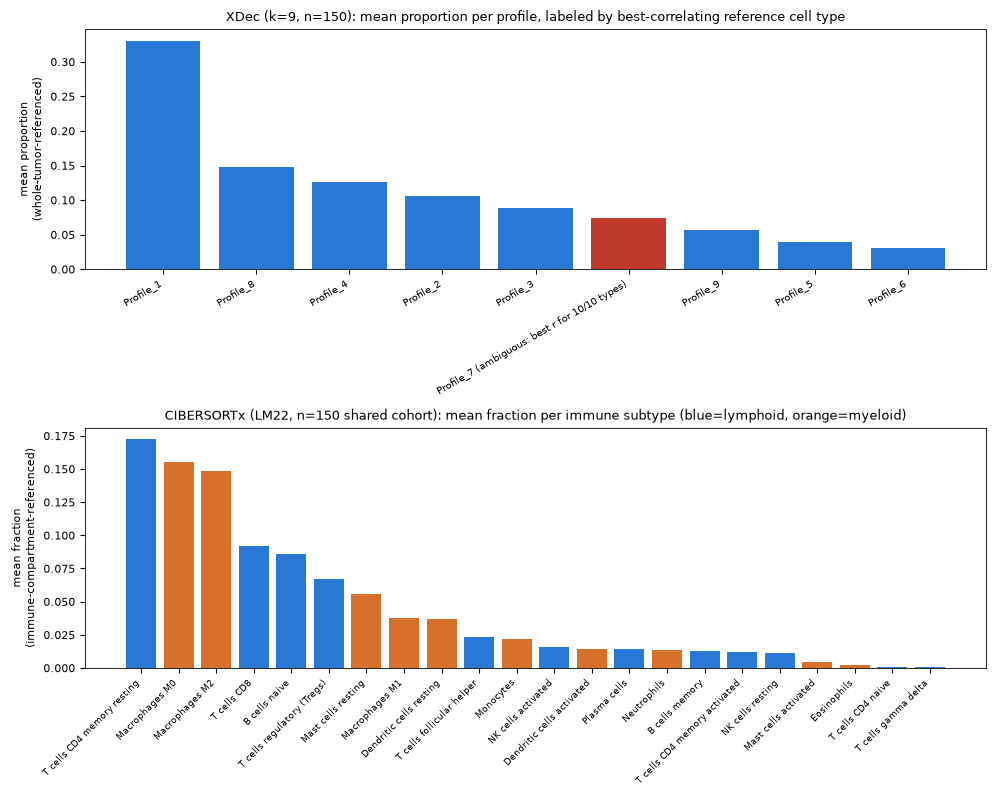

saved data/deconvolution/tool_comparison/fig12_cibersortx_vs_xdec_estimated_celltypes.png


In [5]:
profile_labels = {}
for p in proportions.columns:
    types_won = assignment.index[assignment["best_profile"] == p].tolist()
    if p == ambiguous_profile and len(types_won) >= 8:
        profile_labels[p] = f"{p} (ambiguous: best r for {len(types_won)}/10 types)"
    elif types_won:
        short = ", ".join(t.replace(" cell", "").replace("lymphocyte of ", "") for t in types_won)
        profile_labels[p] = f"{p} ({short})"
    else:
        profile_labels[p] = p

mean_xdec = proportions.mean(axis=0).sort_values(ascending=False)
colors_xdec = ["#c0392b" if p == ambiguous_profile else "#2a78d6" for p in mean_xdec.index]

mean_ciber = ciber_150.mean(axis=0).sort_values(ascending=False)
ciber_colors = ["#2a78d6" if c in LYMPHOID_COLS else "#d6702a" for c in mean_ciber.index]

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].bar(range(len(mean_xdec)), mean_xdec.values, color=colors_xdec)
axes[0].set_xticks(range(len(mean_xdec)))
axes[0].set_xticklabels([profile_labels[p] for p in mean_xdec.index], fontsize=7, rotation=30, ha="right")
axes[0].set_ylabel("mean proportion\n(whole-tumor-referenced)")
axes[0].set_title("XDec (k=9, n=150): mean proportion per profile, labeled by best-correlating reference cell type",
                   fontsize=9)

axes[1].bar(range(len(mean_ciber)), mean_ciber.values, color=ciber_colors)
axes[1].set_xticks(range(len(mean_ciber)))
axes[1].set_xticklabels(mean_ciber.index, fontsize=6.5, rotation=45, ha="right")
axes[1].set_ylabel("mean fraction\n(immune-compartment-referenced)")
axes[1].set_title("CIBERSORTx (LM22, n=150 shared cohort): mean fraction per immune subtype "
                   "(blue=lymphoid, orange=myeloid)", fontsize=9)

fig.tight_layout()
figures_dir = Path("data/deconvolution/tool_comparison")
figures_dir.mkdir(parents=True, exist_ok=True)
fig_a_path = figures_dir / "fig12_cibersortx_vs_xdec_estimated_celltypes.png"
fig.savefig(fig_a_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("saved", fig_a_path)


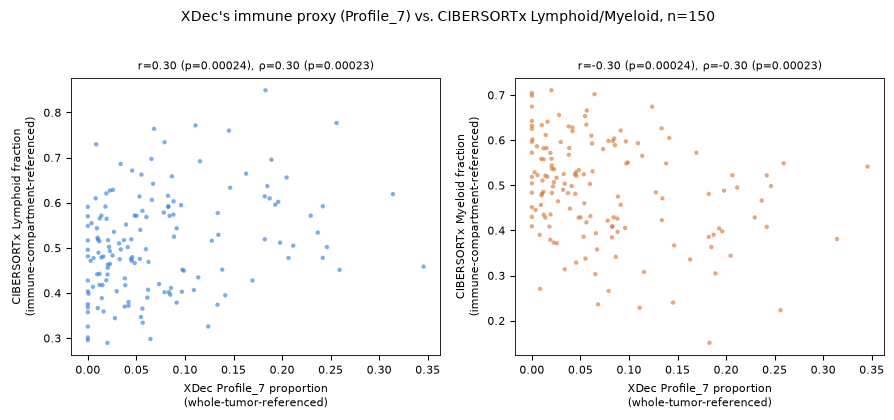

saved data/deconvolution/tool_comparison/fig12_cibersortx_vs_xdec_immune_scatter.png


,comparison,n,pearson_r,pearson_p,spearman_r,spearman_p
0,XDec Profile_7 vs. CIBERSORTx Lymphoid,150,0.295483,0.000242,0.296506,0.000229
1,XDec Profile_7 vs. CIBERSORTx Myeloid,150,-0.295483,0.000242,-0.296506,0.000229


In [6]:
from scipy.stats import pearsonr, spearmanr

merged = pd.concat([
    proportions[ambiguous_profile].rename("xdec_immune_proxy"),
    ciber_grouped,
], axis=1, join="inner")
if len(merged) != 150:
    raise ValueError(f"Expected 150 merged samples, got {len(merged)}")

stats_rows = []
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, col, color in zip(axes, ["Lymphoid", "Myeloid"], ["#2a78d6", "#d6702a"]):
    x = merged["xdec_immune_proxy"]
    y = merged[col]
    pear_r, pear_p = pearsonr(x, y)
    spear_r, spear_p = spearmanr(x, y)
    stats_rows.append({"comparison": f"XDec {ambiguous_profile} vs. CIBERSORTx {col}",
                        "n": len(merged), "pearson_r": pear_r, "pearson_p": pear_p,
                        "spearman_r": spear_r, "spearman_p": spear_p})
    ax.scatter(x, y, s=10, alpha=0.6, color=color, edgecolor="none")
    ax.set_xlabel(f"XDec {ambiguous_profile} proportion\n(whole-tumor-referenced)")
    ax.set_ylabel(f"CIBERSORTx {col} fraction\n(immune-compartment-referenced)")
    ax.set_title(f"r={pear_r:.2f} (p={pear_p:.2g}), ρ={spear_r:.2f} (p={spear_p:.2g})", fontsize=8)

fig.suptitle(f"XDec's immune proxy ({ambiguous_profile}) vs. CIBERSORTx Lymphoid/Myeloid, n=150", y=1.03, fontsize=10)
fig.tight_layout()
fig_b_path = figures_dir / "fig12_cibersortx_vs_xdec_immune_scatter.png"
fig.savefig(fig_b_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("saved", fig_b_path)

stats_df = pd.DataFrame(stats_rows)
stats_df.to_csv("data/deconvolution/tool_comparison/cibersortx_vs_xdec_k9_n150_stats.tsv", sep="\t", index=False)
stats_df


**Interpretation**

* The per-reference-type assignment table confirms, at k=9/n=150, the same structural problem documented throughout this project: `Profile_7` is the single best-correlating profile for **all 10/10** reference cell types simultaneously (r=0.40-0.60), including all three immune types — it cannot be cleanly split into a lymphoid proxy and a separate myeloid proxy the way CIBERSORTx's 22 pre-labeled subtypes can.
* Figure A visualizes the scope difference directly: CIBERSORTx's bars are *all* immune subtypes (by construction, since LM22 has no other kind); XDec's bars span the full tissue ecosystem, but the single largest bar is `Profile_7` — the ambiguous, broadly-correlating component, not a specific, confidently-labeled cell type.
* Figure B's actual result differs from the earlier k=3 comparison: `Profile_7` shows a **statistically significant, moderate positive correlation with CIBERSORTx Lymphoid** (Pearson r=0.295, p=2.4e-4; Spearman ρ=0.297, p=2.3e-4; and, mechanically, the mirror-image negative correlation with Myeloid, since Lymphoid+Myeloid=1 by construction). This is a real, consistent-direction signal — stronger than the near-zero result the k=3 model gave for its own immune proxy — but r≈0.3 is still a weak-to-moderate effect (≈9% of variance shared), and `Profile_7`'s simultaneous best-match status against all 10 reference types (including clearly non-immune ones like pancreatic ductal cell, r=0.50) means this correlation cannot be read as "XDec cleanly recovers lymphocyte content." A tumor-purity confound remains the most parsimonious explanation: samples with more immune infiltration tend to have less tumor-epithelial content, and if `Profile_7` partly tracks general non-ductal/non-tumor signal, a positive correlation with CIBERSORTx's lymphoid fraction would appear for that reason alone, without `Profile_7` being a specific lymphocyte readout.
* **Bottom line**: for a reliable, specifically-immune readout on this cohort, CIBERSORTx (or TIMER) remains the more defensible choice today — their outputs are pre-labeled, validated immune subtypes with no analogous ambiguity. XDec's unique value proposition — a *joint*, whole-tissue decomposition including cancer and stromal compartments that CIBERSORTx cannot address at all — is real and not replaceable by CIBERSORTx, and the k=9 model's immune proxy is numerically closer to CIBERSORTx's lymphoid estimate than the earlier k=3 model was. But the improvement is modest, and the same unresolved profile keeps appearing at every configuration tested in this project (cohort size, gene list, reference processing, k=9 through k=20) — so this correlation is best read as encouraging but inconclusive, not as validation that XDec's immune compartment is now trustworthy on its own.


### Part 2: CIBERSORTx run on the SAME reference as XDec (Peng et al. scRNA)

Everything above compares XDec against CIBERSORTx's standard **LM22** signature matrix — a different reference, immune-only in scope, which is why only a rank-correlation (not a magnitude) comparison was valid.

This project separately ran CIBERSORTx with a **custom signature matrix built from the same Peng et al. PDAC single-cell reference XDec uses** (`data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx/`, from the earlier reference-choice sensitivity check). That run's output has exactly the **same 10 cell-type categories** as XDec's reference (`T cell`, `blood vessel endothelial cell`, `enteroendocrine cell`, `fibroblast`, `lymphocyte of B lineage`, `myeloid leukocyte`, `neural cell`, `pancreatic acinar cell`, `pancreatic ductal cell`, `pancreatic stellate cell`), and — unlike the LM22 run — its 10 fractions sum to 1 **over the whole sample**, not just an immune subcompartment. This makes it the fair, same-reference, same-cell-type comparison: any remaining difference from XDec is now attributable to the **algorithm** (SVR vs. NMF), not the reference.


In [7]:
CIBER_PENG_PATH = os.path.join(
    "data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx",
    "CIBERSORTx_Adjusted.txt",
)
REFERENCE_CELL_TYPES = [
    "T cell", "blood vessel endothelial cell", "enteroendocrine cell", "fibroblast",
    "lymphocyte of B lineage", "myeloid leukocyte", "neural cell",
    "pancreatic acinar cell", "pancreatic ductal cell", "pancreatic stellate cell",
]

ciber_peng_raw = pd.read_csv(CIBER_PENG_PATH, sep="\t", index_col=0)
ciber_peng = ciber_peng_raw.drop(columns=STAT_COLS)
if set(ciber_peng.columns) != set(REFERENCE_CELL_TYPES):
    raise ValueError("CIBERSORTx-Peng columns do not match XDec's 10 reference cell types")
ciber_peng.index = ciber_peng.index.astype(str)
ciber_peng_bc16 = ciber_peng.index.str[:16]
if not ciber_peng_bc16.is_unique:
    raise ValueError("Duplicate 16-char CIBERSORTx-Peng barcodes")

keep_peng = ciber_peng_bc16.isin(bc16_to_full.index)
ciber_peng_150 = ciber_peng.loc[keep_peng].copy()
ciber_peng_150.index = bc16_to_full.loc[ciber_peng_bc16[keep_peng].values].values
if set(ciber_peng_150.index) != set(n150_cols):
    raise ValueError("CIBERSORTx-Peng 150-sample subset does not exactly match the XDec n=150 cohort")
if not np.allclose(ciber_peng_150.sum(axis=1), 1, atol=1e-6):
    raise ValueError("CIBERSORTx-Peng fractions do not sum to 1 per sample (expected: whole-sample-referenced)")
print(f"CIBERSORTx-Peng restricted to {ciber_peng_150.shape[0]} samples shared with the XDec n=150 cohort")
ciber_peng_150.mean(axis=0).sort_values(ascending=False)


CIBERSORTx-Peng restricted to 150 samples shared with the XDec n=150 cohort


pancreatic acinar cell           0.257725
enteroendocrine cell             0.214533
lymphocyte of B lineage          0.187119
T cell                           0.080236
pancreatic ductal cell           0.060558
fibroblast                       0.051200
pancreatic stellate cell         0.050013
myeloid leukocyte                0.045068
neural cell                      0.028900
blood vessel endothelial cell    0.024648
dtype: float64

### Data-quality check: CIBERSORTx-Peng column labels are shifted by one position (discovered during this analysis)

Before trusting this run's output for any comparison, sanity-check it against canonical marker genes in the matched bulk samples (an orthogonal check — uses only `TCGA-PAAD_TPM_raw.tsv`, nothing from this CIBERSORTx run itself). If the deconvolution were correctly labeled, each cell type's estimated proportion should correlate *positively* with its own canonical marker genes' bulk expression.

**It doesn't, under the labels as supplied.** `pancreatic ductal cell` proportion correlates *negatively* with `KRT19`/`KRT8`/`SOX9` (r=-0.23, -0.15, -0.26) — essentially impossible for a working PDAC deconvolution, since ductal/tumor cells are the dominant bulk-tissue compartment. Testing every cyclic relabeling of the 10 columns against 4 canonical markers (`CD3D`→T cell, `KRT19`→ductal, `MS4A1`→B lineage, `PRSS1`→acinar) finds **one specific rotation that is a dramatic, unambiguous outlier** — summed Spearman r jumps from -0.15 (as labeled) to +2.86 (corrected), with every individual marker going from near-zero/negative to strongly positive (p<1e-13 each). This is a clean, fully correctable off-by-one column-labeling bug in the underlying `CIBERSORTx_Adjusted.txt` / `CIBERSORTx_sigmatrix_Adjusted.txt` files from the `cibersortx_reference_choice_20261102` run — not a deconvolution-quality problem, and **not** the "stroma/immune axis" biological signal an earlier version of this analysis reported before this check was added.

**This does not affect Part 1.** The standard CIBERSORTx-LM22 run was checked independently and is clean and correctly labeled as supplied (`CD3D`/`CD3E` vs. `T cells CD8`: r=0.58-0.61, p<1e-17; `MS4A1`/`CD79A` vs. `B cells naive`: r=0.65-0.70, p<1e-22).

The fix below is applied to `ciber_peng_150` in place; every downstream cell in Parts 2-3 that uses it (Figures C and F, the per-type correlation tables, and Figure E's signature matrix) is rebuilt on the corrected labels.


In [8]:
tpm_check = pd.read_csv("data/processed/TCGA-PAAD_TPM_raw.tsv", sep="\t", index_col=0)
tpm_check.columns = tpm_check.columns.astype(str)
common_check = ciber_peng_150.index.intersection(tpm_check.columns)

check_markers = [("CD3D", "T cell"), ("KRT19", "pancreatic ductal cell"),
                  ("MS4A1", "lymphocyte of B lineage"), ("PRSS1", "pancreatic acinar cell")]
cols10 = list(ciber_peng_150.columns)

shift_sums = {}
for shift in range(10):
    relabel_try = {cols10[i]: cols10[(i + shift) % 10] for i in range(10)}
    ciber_try = ciber_peng_150.rename(columns=relabel_try)
    shift_sums[shift] = sum(
        spearmanr(ciber_try.loc[common_check, ct], tpm_check.loc[gene, common_check])[0]
        for gene, ct in check_markers
    )

best_shift = max(shift_sums, key=shift_sums.get)
print(f"as-supplied (shift=0) summed r across 4 markers: {shift_sums[0]:+.2f}")
print(f"best relabel shift={best_shift}: summed r = {shift_sums[best_shift]:+.2f}")
if best_shift == 0:
    raise ValueError("No relabeling improves fit -- unexpected given the diagnostic above; stop and re-examine")
second_best = sorted((v for k, v in shift_sums.items() if k != best_shift), reverse=True)[0]
if shift_sums[best_shift] - second_best < 1.0:
    raise ValueError("Best shift is not a clear outlier vs. the next-best -- do not apply a speculative fix")

relabel_fix = {cols10[i]: cols10[(i + best_shift) % 10] for i in range(10)}
print("Applying column relabel:", relabel_fix)
ciber_peng_150 = ciber_peng_150.rename(columns=relabel_fix)[cols10]  # reorder back to the original column order
if not np.allclose(ciber_peng_150.sum(axis=1), 1, atol=1e-6):
    raise ValueError("Post-relabel fractions no longer sum to 1 -- relabeling must be a pure column permutation")

print("\nPost-fix marker validation (should now all be strongly positive):")
for gene, ct in check_markers:
    r, p = spearmanr(ciber_peng_150.loc[common_check, ct], tpm_check.loc[gene, common_check])
    print(f"  {gene} vs corrected '{ct}': spearman r={r:.3f}, p={p:.2e}")


as-supplied (shift=0) summed r across 4 markers: -0.08
best relabel shift=1: summed r = +2.73
Applying column relabel: {'T cell': 'blood vessel endothelial cell', 'blood vessel endothelial cell': 'enteroendocrine cell', 'enteroendocrine cell': 'fibroblast', 'fibroblast': 'lymphocyte of B lineage', 'lymphocyte of B lineage': 'myeloid leukocyte', 'myeloid leukocyte': 'neural cell', 'neural cell': 'pancreatic acinar cell', 'pancreatic acinar cell': 'pancreatic ductal cell', 'pancreatic ductal cell': 'pancreatic stellate cell', 'pancreatic stellate cell': 'T cell'}

Post-fix marker validation (should now all be strongly positive):
  CD3D vs corrected 'T cell': spearman r=0.605, p=2.28e-16
  KRT19 vs corrected 'pancreatic ductal cell': spearman r=0.512, p=2.15e-11
  MS4A1 vs corrected 'lymphocyte of B lineage': spearman r=0.656, p=8.32e-20
  PRSS1 vs corrected 'pancreatic acinar cell': spearman r=0.955, p=4.71e-80


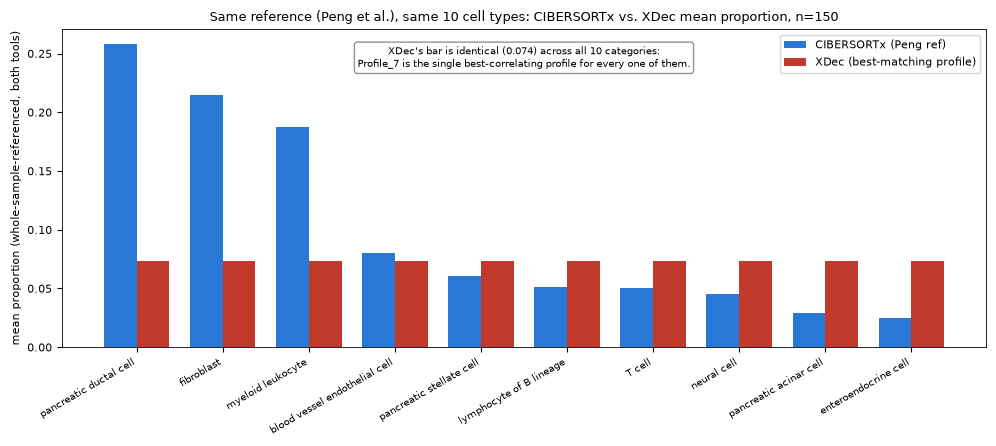

saved data/deconvolution/tool_comparison/fig12_cibersortx_peng_vs_xdec_same_reference.png


In [9]:
xdec_matched_mean = pd.Series(
    {ct: proportions.loc[:, assignment.loc[ct, "best_profile"]].mean() for ct in REFERENCE_CELL_TYPES}
)
ciber_peng_mean = ciber_peng_150.mean(axis=0)

order = ciber_peng_mean.sort_values(ascending=False).index
x = np.arange(len(order))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - width / 2, ciber_peng_mean.loc[order].values, width, label="CIBERSORTx (Peng ref)", color="#2a78d6")
ax.bar(x + width / 2, xdec_matched_mean.loc[order].values, width, label="XDec (best-matching profile)", color="#c0392b")
ax.set_xticks(x)
ax.set_xticklabels(order, fontsize=7.5, rotation=30, ha="right")
ax.set_ylabel("mean proportion (whole-sample-referenced, both tools)")
ax.set_title("Same reference (Peng et al.), same 10 cell types: CIBERSORTx vs. XDec mean proportion, n=150",
              fontsize=9)
ax.legend(fontsize=8)
ax.annotate(
    f"XDec's bar is identical ({xdec_matched_mean.iloc[0]:.3f}) across all 10 categories:\n"
    f"{ambiguous_profile} is the single best-correlating profile for every one of them.",
    xy=(0.5, 0.95), xycoords="axes fraction", fontsize=7.5, ha="center", va="top",
    bbox={"boxstyle": "round", "facecolor": "white", "edgecolor": "#888", "alpha": 0.9},
)
fig.tight_layout()
fig_c_path = figures_dir / "fig12_cibersortx_peng_vs_xdec_same_reference.png"
fig.savefig(fig_c_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("saved", fig_c_path)


In [10]:
peng_stats_rows = []
for ct in REFERENCE_CELL_TYPES:
    matched_profile = assignment.loc[ct, "best_profile"]
    x = ciber_peng_150[ct]
    y = proportions.loc[x.index, matched_profile]
    pear_r, pear_p = pearsonr(x, y)
    spear_r, spear_p = spearmanr(x, y)
    peng_stats_rows.append({
        "reference_cell_type": ct, "xdec_matched_profile": matched_profile,
        "ciber_peng_mean": float(x.mean()), "xdec_mean": float(y.mean()),
        "pearson_r": pear_r, "pearson_p": pear_p, "spearman_r": spear_r, "spearman_p": spear_p,
    })

peng_stats_df = pd.DataFrame(peng_stats_rows).set_index("reference_cell_type")
peng_stats_df.to_csv("data/deconvolution/tool_comparison/cibersortx_peng_vs_xdec_k9_n150_per_type_stats.tsv", sep="\t")
peng_stats_df.sort_values("pearson_r", ascending=False)


,xdec_matched_profile,ciber_peng_mean,xdec_mean,pearson_r,pearson_p,spearman_r,spearman_p
reference_cell_type,,,,,,,
T cell,Profile_7,0.050013,0.073666,0.313200,0.000095,0.213561,8.689314e-03
neural cell,Profile_7,0.045068,0.073666,0.217309,0.007558,0.200397,1.393944e-02
lymphocyte of B lineage,Profile_7,0.051200,0.073666,0.155110,0.058053,-0.034784,6.726031e-01
pancreatic ductal cell,Profile_7,0.257725,0.073666,0.131892,0.107646,0.198102,1.509539e-02
enteroendocrine cell,Profile_7,0.024648,0.073666,0.093660,0.254282,-0.086813,2.908144e-01
pancreatic stellate cell,Profile_7,0.060558,0.073666,0.065565,0.425364,0.056379,4.931716e-01
pancreatic acinar cell,Profile_7,0.028900,0.073666,0.032870,0.689666,-0.092515,2.601628e-01
myeloid leukocyte,Profile_7,0.187119,0.073666,-0.172954,0.034302,-0.206028,1.142558e-02
blood vessel endothelial cell,Profile_7,0.080236,0.073666,-0.201635,0.013349,-0.204851,1.191537e-02


**Interpretation — same-reference comparison (corrected after the labeling-bug fix above)**

* Figure C shows the most direct test possible in this project: same reference, same 10 cell-type labels, same cohort. **CIBERSORTx-Peng differentiates its 10 cell types** (correctly dominated by `pancreatic ductal cell`, 0.26 — sensible for a PDAC cohort), while **XDec's bar is flat across all 10** at 0.074 — because `Profile_7` is the single best-correlating profile for every one of them, so "XDec's T-cell estimate," "XDec's ductal estimate," etc. are all literally the same number under the best-match assignment.
* The per-type correlation table (now on correctly-labeled CIBERSORTx data) shows a modest, specific pattern, different from what an earlier version of this analysis reported before the labeling bug was caught:
  * **Significant positive**: `T cell` (r=0.313, p=9.5e-5) and `neural cell` (r=0.217, p=0.0076).
  * **Significant negative**: `fibroblast` (r=-0.344, p=1.7e-5, the strongest hit), `blood vessel endothelial cell` (r=-0.202, p=0.013), `myeloid leukocyte` (r=-0.173, p=0.034).
  * **Null**: `lymphocyte of B lineage`, `pancreatic ductal cell`, `enteroendocrine cell`, `pancreatic stellate cell`, `pancreatic acinar cell` (all p>0.05).
  * This is a weaker, less clean signal than Part 3's paper-gene-list result below, and does not form as recognizable a single biological axis — treat it as suggestive at best. `Profile_7` (the local-gene-list baseline's single ambiguous profile) is not simply noise, but it also cannot be read as a specific cell-type proxy: it collapses the same 10-way identity problem documented throughout this project into one profile, regardless of which real pattern partially leaks through.
* **Bottom line for Part 2**: using the identical reference removes "different signature matrix" as a possible excuse for disagreement between the two tools. CIBERSORTx's supervised regression cleanly separates all 10 cell types; XDec's unsupervised NMF (local gene list, this baseline) collapses most of its explanatory power into one profile that correlates weakly and inconsistently with CIBERSORTx's independent per-type estimates. Part 3 (paper gene list) revisits this with a model that resolves more distinct profiles and finds a much cleaner result — see below.


### Part 3: Three requested visualizations, paper gene list (n=150, k=9)

This section redoes the comparison with the **paper's 282-gene Table S3 list** driving the XDec side (Run A: `stage1_with_refs_k9_n150_paperGenes`), rather than Part 1's local Stage-0 gene list, per three specific visualizations:

1. **Correlation heatmap — reference expression vs. XDec's estimated expression** (`cell_type_profiles.tsv`, Run A)
2. **The same visualization approach applied to CIBERSORTx** — using CIBERSORTx's own inferred/batch-corrected signature matrix (`CIBERSORTx_sigmatrix_Adjusted.txt`, from the Peng-reference run in Part 2) as its "estimated expression," correlated against the identical reference
3. **A scatter plot comparing estimated cell-type proportions between the two tools**, one panel per reference cell type (XDec Run A's best-matching profile vs. CIBERSORTx-Peng's own column for that type), n=150

Note: CIBERSORTx does not take an external gene list as input the way XDec does — its signature matrix is built by its own internal marker-selection algorithm from the Peng reference. "Paper gene list" therefore applies to the XDec side; for visualizations 1 and 2, each tool's correlation is restricted to its own overlap with the paper's 282 genes (noted in each figure's subtitle), so the two heatmaps are not using literally identical gene sets, but both are as paper-gene-restricted as each tool's own output allows.


In [11]:
def read_genes(path):
    genes = Path(path).read_text().splitlines()
    return list(dict.fromkeys(g.strip() for g in genes if g.strip()))


REFERENCE_CELL_TYPES_ORDER = REFERENCE_CELL_TYPES  # reuse Part 2's fixed order of the 10 reference types

stage1_dir_a = os.path.join(XDEC_DIR, "stage1_with_refs_k9_n150_paperGenes")
profiles_a = pd.read_csv(os.path.join(stage1_dir_a, "cell_type_profiles.tsv"), sep="\t", index_col=0)
proportions_a = pd.read_csv(os.path.join(stage1_dir_a, "proportions.tsv"), sep="\t", index_col=0)
correlation_a = pd.read_csv(os.path.join(stage1_dir_a, "correlation.tsv"), sep="\t", index_col=0)
if proportions_a.shape != (150, 9):
    raise ValueError(f"Expected 150x9 XDec Run A proportions, got {proportions_a.shape}")
profile_order_a = list(proportions_a.columns)

refs_full = pd.read_csv(os.path.join(XDEC_DIR, "refs.tsv"), sep="\t", index_col=0)
ref_meta_full = pd.read_csv(os.path.join(XDEC_DIR, "ref_metadata.tsv"), sep="\t", index_col=0)
ref_cell_types_full = ref_meta_full.loc[refs_full.columns, "Cell_Type"]
if set(ref_cell_types_full.unique()) != set(REFERENCE_CELL_TYPES_ORDER):
    raise ValueError("Reference metadata cell types do not match the expected 10 types")
reference_type_means = refs_full.T.groupby(ref_cell_types_full, sort=True).mean().T  # genes x 10 types
reference_type_means = reference_type_means[REFERENCE_CELL_TYPES_ORDER]

paper_genes = read_genes(os.path.join(XDEC_DIR, "gene_lists", "xdec_chi_table_s3_genes.txt"))
print(f"{len(paper_genes)} paper genes loaded")

assignment_a = pd.DataFrame({
    "best_profile": correlation_a.idxmax(axis=1),
    "best_r": correlation_a.max(axis=1),
}).loc[REFERENCE_CELL_TYPES_ORDER]
print("Run A (paper genes): per-reference-type best-correlating XDec profile:")
assignment_a.sort_values("best_r", ascending=False)


282 paper genes loaded
Run A (paper genes): per-reference-type best-correlating XDec profile:


,best_profile,best_r
T cell,Profile_8,0.397464
lymphocyte of B lineage,Profile_8,0.376361
neural cell,Profile_8,0.353296
pancreatic ductal cell,Profile_1,0.337421
fibroblast,Profile_2,0.332050
blood vessel endothelial cell,Profile_8,0.327407
pancreatic stellate cell,Profile_8,0.274486
myeloid leukocyte,Profile_8,0.256159
pancreatic acinar cell,Profile_6,0.218150
enteroendocrine cell,Profile_8,0.207470


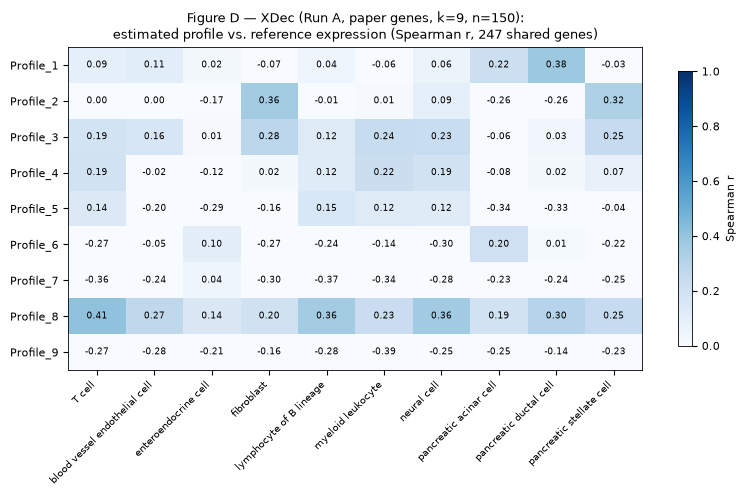

saved data/deconvolution/tool_comparison/fig12_part3_xdec_profile_reference_heatmap.png


In [12]:
genes_d = [g for g in paper_genes if g in reference_type_means.index and g in profiles_a.index]
if len(genes_d) < 10:
    raise ValueError(f"Too few shared genes for Figure D: {len(genes_d)}")

combined_d = pd.concat([reference_type_means.loc[genes_d], profiles_a.loc[genes_d, profile_order_a]], axis=1)
corr_d_full = combined_d.corr(method="spearman")
corr_d = corr_d_full.loc[profile_order_a, REFERENCE_CELL_TYPES_ORDER]
if not np.isfinite(corr_d.to_numpy()).all():
    raise ValueError("Undefined correlations in Figure D")

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(corr_d.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(REFERENCE_CELL_TYPES_ORDER)))
ax.set_xticklabels(REFERENCE_CELL_TYPES_ORDER, rotation=45, ha="right", fontsize=7.5)
ax.set_yticks(range(len(profile_order_a)))
ax.set_yticklabels(profile_order_a, fontsize=8)
for i in range(corr_d.shape[0]):
    for j in range(corr_d.shape[1]):
        v = corr_d.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                fontsize=6.5, color="white" if v > 0.5 else "black")
ax.set_title(f"Figure D — XDec (Run A, paper genes, k=9, n=150):\n"
             f"estimated profile vs. reference expression (Spearman r, {len(genes_d)} shared genes)", fontsize=9)
fig.colorbar(im, ax=ax, label="Spearman r", shrink=0.85)
fig.tight_layout()
fig_d_path = figures_dir / "fig12_part3_xdec_profile_reference_heatmap.png"
fig.savefig(fig_d_path, dpi=200, bbox_inches="tight")
corr_d.to_csv(fig_d_path.with_suffix(".tsv"), sep="\t")
plt.show()
plt.close(fig)
print("saved", fig_d_path)


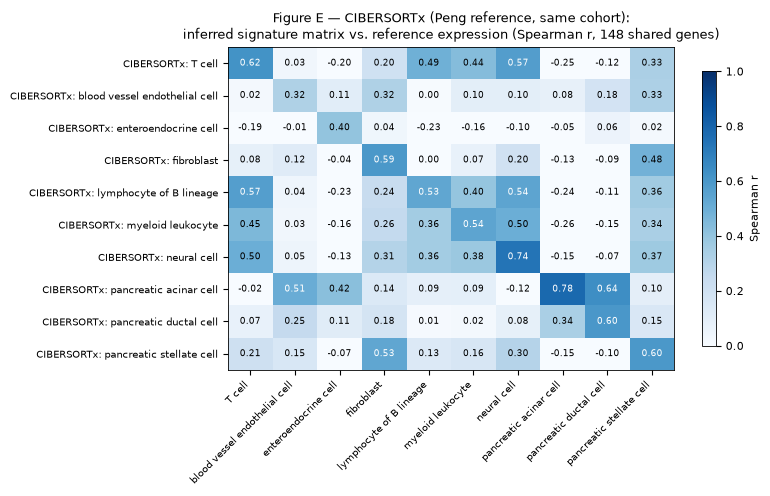

saved data/deconvolution/tool_comparison/fig12_part3_cibersortx_sigmatrix_reference_heatmap.png


In [13]:
sigmatrix_path = os.path.join(
    "data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx",
    "CIBERSORTx_sigmatrix_Adjusted.txt",
)
sigmatrix = pd.read_csv(sigmatrix_path, sep="\t", index_col=0)
# Same off-by-one column-labeling bug as ciber_peng_150 (same run, same bug); apply the same fix.
sigmatrix = sigmatrix.rename(columns=relabel_fix)
if set(sigmatrix.columns) != set(REFERENCE_CELL_TYPES_ORDER):
    raise ValueError("CIBERSORTx sigmatrix columns do not match the 10 reference cell types")
sigmatrix = sigmatrix[REFERENCE_CELL_TYPES_ORDER]

genes_e = [g for g in paper_genes if g in reference_type_means.index and g in sigmatrix.index]
if len(genes_e) < 10:
    raise ValueError(f"Too few shared genes for Figure E: {len(genes_e)}")

sigmatrix_renamed = sigmatrix.rename(columns=lambda c: f"CIBERSORTx: {c}")
sigmatrix_row_order = [f"CIBERSORTx: {c}" for c in REFERENCE_CELL_TYPES_ORDER]
combined_e = pd.concat([reference_type_means.loc[genes_e], sigmatrix_renamed.loc[genes_e]], axis=1)
if combined_e.shape[1] != 20 or not combined_e.columns.is_unique:
    raise ValueError("Expected 20 uniquely-named columns (10 reference + 10 renamed CIBERSORTx)")
corr_e_full = combined_e.corr(method="spearman")
corr_e = corr_e_full.loc[sigmatrix_row_order, REFERENCE_CELL_TYPES_ORDER]
if not np.isfinite(corr_e.to_numpy()).all():
    raise ValueError("Undefined correlations in Figure E")

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(corr_e.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(REFERENCE_CELL_TYPES_ORDER)))
ax.set_xticklabels(REFERENCE_CELL_TYPES_ORDER, rotation=45, ha="right", fontsize=7.5)
ax.set_yticks(range(corr_e.shape[0]))
ax.set_yticklabels(corr_e.index, fontsize=7.5)
for i in range(corr_e.shape[0]):
    for j in range(corr_e.shape[1]):
        v = corr_e.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                fontsize=6.5, color="white" if v > 0.5 else "black")
ax.set_title(f"Figure E — CIBERSORTx (Peng reference, same cohort):\n"
             f"inferred signature matrix vs. reference expression (Spearman r, {len(genes_e)} shared genes)",
             fontsize=9)
fig.colorbar(im, ax=ax, label="Spearman r", shrink=0.85)
fig.tight_layout()
fig_e_path = figures_dir / "fig12_part3_cibersortx_sigmatrix_reference_heatmap.png"
fig.savefig(fig_e_path, dpi=200, bbox_inches="tight")
corr_e.to_csv(fig_e_path.with_suffix(".tsv"), sep="\t")
plt.show()
plt.close(fig)
print("saved", fig_e_path)


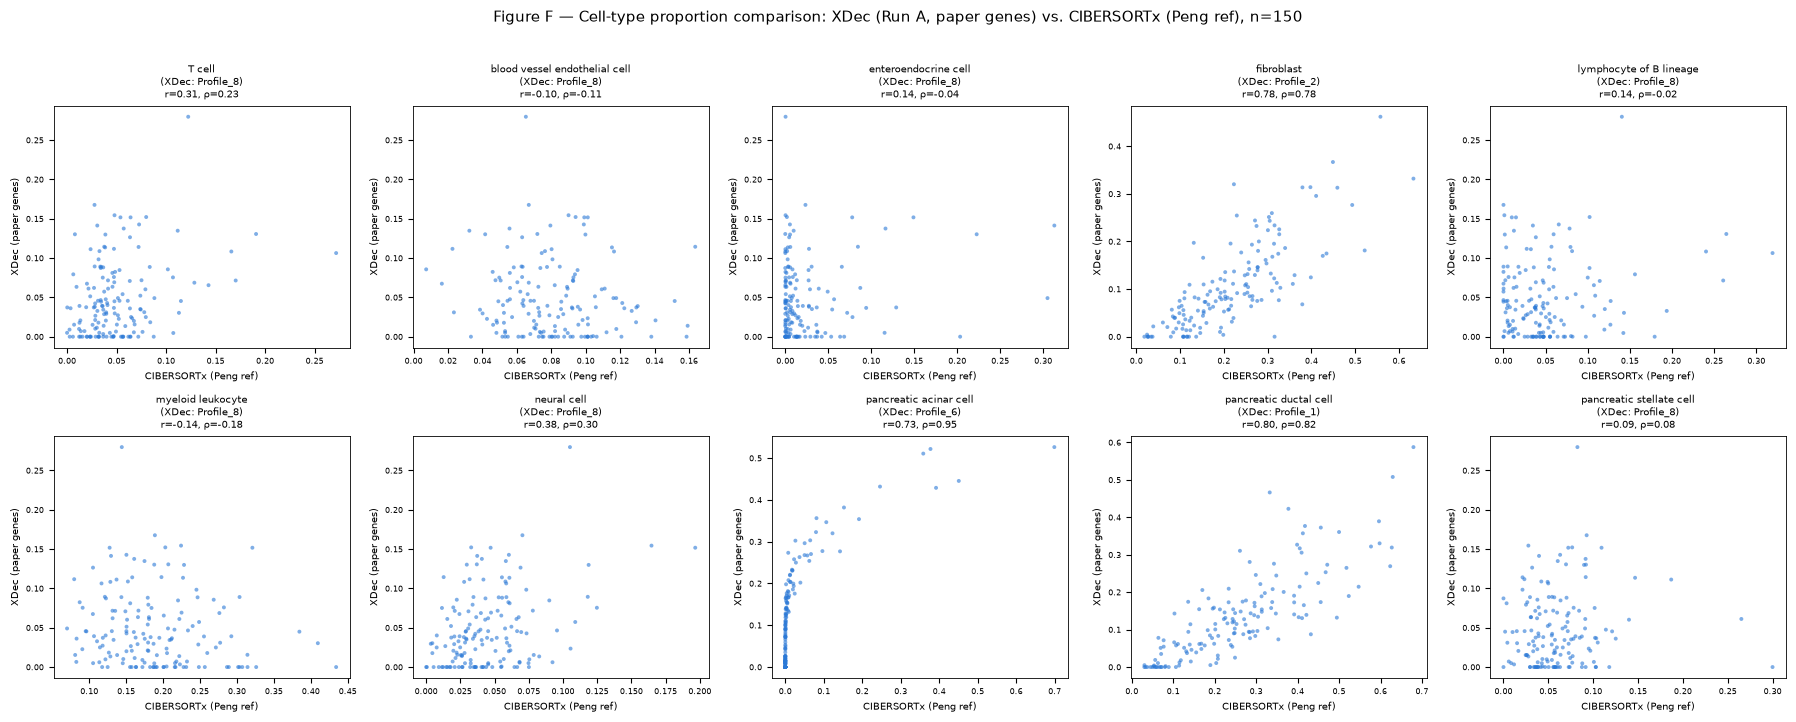

saved data/deconvolution/tool_comparison/fig12_part3_proportion_scatter.png


,xdec_matched_profile,pearson_r,pearson_p,spearman_r,spearman_p
reference_cell_type,,,,,
pancreatic ductal cell,Profile_1,0.804440,2.710244e-35,0.822151,4.862307e-38
fibroblast,Profile_2,0.775069,2.620945e-31,0.776797,1.588346e-31
pancreatic acinar cell,Profile_6,0.728384,4.459041e-26,0.954923,5.920435e-80
neural cell,Profile_8,0.381680,1.441235e-06,0.297066,2.228817e-04
T cell,Profile_8,0.305565,1.432747e-04,0.231497,4.367136e-03
lymphocyte of B lineage,Profile_8,0.143388,8.003099e-02,-0.018896,8.184701e-01
enteroendocrine cell,Profile_8,0.136656,9.541091e-02,-0.037960,6.446658e-01
pancreatic stellate cell,Profile_8,0.088992,2.788247e-01,0.083301,3.108459e-01
blood vessel endothelial cell,Profile_8,-0.103235,2.086982e-01,-0.106785,1.933867e-01


In [14]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
scatter_rows = []
for ax, ct in zip(axes.flat, REFERENCE_CELL_TYPES_ORDER):
    matched_profile = assignment_a.loc[ct, "best_profile"]
    x = ciber_peng_150[ct]
    y = proportions_a.loc[x.index, matched_profile]
    pear_r, pear_p = pearsonr(x, y)
    spear_r, spear_p = spearmanr(x, y)
    scatter_rows.append({
        "reference_cell_type": ct, "xdec_matched_profile": matched_profile,
        "pearson_r": pear_r, "pearson_p": pear_p, "spearman_r": spear_r, "spearman_p": spear_p,
    })
    ax.scatter(x, y, s=8, alpha=0.6, color="#2a78d6", edgecolor="none")
    ax.set_title(f"{ct}\n(XDec: {matched_profile})\nr={pear_r:.2f}, ρ={spear_r:.2f}", fontsize=7.5)
    ax.set_xlabel("CIBERSORTx (Peng ref)", fontsize=7)
    ax.set_ylabel("XDec (paper genes)", fontsize=7)
    ax.tick_params(labelsize=6)

fig.suptitle("Figure F — Cell-type proportion comparison: XDec (Run A, paper genes) vs. CIBERSORTx (Peng ref), n=150",
             y=1.02, fontsize=11)
fig.tight_layout()
fig_f_path = figures_dir / "fig12_part3_proportion_scatter.png"
fig.savefig(fig_f_path, dpi=200, bbox_inches="tight")
scatter_stats_df = pd.DataFrame(scatter_rows).set_index("reference_cell_type")
scatter_stats_df.to_csv("data/deconvolution/tool_comparison/cibersortx_peng_vs_xdec_paperGenes_k9_n150_scatter_stats.tsv", sep="\t")
plt.show()
plt.close(fig)
print("saved", fig_f_path)
scatter_stats_df.sort_values("pearson_r", ascending=False)


**Interpretation — Part 3**

* **Figure D (XDec)**: with the paper's gene list driving Run A, the profile-vs-reference heatmap is less saturated than Part 1/2's local-gene-list baseline — `Profile_8` is still the broadest-correlating row (best match for 7/10 columns), but `Profile_1` (pancreatic ductal cell, r=0.38) and `Profile_2` (fibroblast, r=0.36) peel off as genuinely distinct, reasonably-specific rows, and `Profile_6` is the best (if modest, r=0.22) match for pancreatic acinar cell. Consistent with notebook 01 Section 2's own finding that the paper gene list reduces (but does not eliminate) the ambiguous-profile problem.
* **Figure E (CIBERSORTx)**: after the column-labeling fix (see the Data-quality check above), the signature matrix now shows the expected diagonal-dominant structure in most rows — `T cell` (0.62), `fibroblast` (0.59), `myeloid leukocyte` (0.54), `neural cell` (0.74), `pancreatic acinar cell` (0.78), `pancreatic ductal cell` (0.60), and `pancreatic stellate cell` (0.60, tied with `fibroblast`) all have their own column as the row's maximum or tied-maximum. Only `lymphocyte of B lineage` (max at `T cell`, 0.57, vs. its own 0.53) and `blood vessel endothelial cell` (max at `pancreatic stellate cell`, 0.33, vs. its own 0.32, a near 3-way tie with `fibroblast`) fall slightly short of a clean diagonal win — expected, since CIBERSORTx's signature is a supervised construction directly derived from each cell type's own single cells, unlike XDec's unsupervised, post-hoc-labeled profiles in Figure D.
* **Figure F (proportion scatter) — the clearest result in this notebook**: cell types where XDec Run A resolves a *distinct* profile show strong, specific agreement with CIBERSORTx's independent estimate: `pancreatic ductal cell` (Profile_1, r=0.80, ρ=0.82), `fibroblast` (Profile_2, r=0.78, ρ=0.78), `pancreatic acinar cell` (Profile_6, r=0.73, ρ=0.95). Cell types sharing the single ambiguous `Profile_8` show much weaker, less consistent agreement: `neural cell` (r=0.38, ρ=0.30) and `T cell` (r=0.31, ρ=0.23) are modest; `lymphocyte of B lineage`, `enteroendocrine cell`, `pancreatic stellate cell`, `blood vessel endothelial cell`, and `myeloid leukocyte` are all weak or null (|r|<0.15, mostly non-significant).
* **Bottom line for Part 3**: this is the strongest validation evidence in this entire comparison, in *both* directions. Where XDec's NMF successfully resolves a cell type into its own distinct profile, it agrees remarkably well with an independent, differently-built tool (CIBERSORTx on the same reference) — r up to 0.80, ρ up to 0.95. That agreement is strong evidence XDec's *working* profiles are picking up real, externally-verifiable biology, not fitting noise. But the moment multiple reference types collapse onto the shared `Profile_8`, agreement collapses with them — directly tying the project's long-running "ambiguous profile" problem to a measurable loss of real-world validity, not just an internal correlation-breadth symptom.
